In [1]:
import pandas as pd
import numpy as np
import cv2    
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models, datasets
from IPython.core.display import display, HTML
from PIL import Image
from io import BytesIO
import base64

plt.style.use('ggplot')



In [2]:
# Set random seeds for reproducibility
torch.manual_seed(42)

In [7]:
# Loading dataset containing different attributes for each image 
df = pd.read_csv('/kaggle/input/celeba-dataset/list_attr_celeba.csv')
df

,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,-1,-1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
202595,202596.jpg,-1,-1,-1,-1,-1,1,1,-1,-1,...,-1,1,1,-1,-1,-1,-1,-1,-1,1
202596,202597.jpg,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
202597,202598.jpg,-1,1,1,-1,-1,-1,1,-1,1,...,-1,1,-1,1,1,-1,1,-1,-1,1


In [8]:
df.replace(to_replace=-1, value=0, inplace=True)
df.set_index('image_id', inplace=True)
df.head()

,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,Blond_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
image_id,,,,,,,,,,,,,,,,,,,,,
000001.jpg,0,1,1,0,0,0,0,0,0,0,...,0,1,1,0,1,0,1,0,0,1
000002.jpg,0,0,0,1,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,1
000003.jpg,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1
000004.jpg,0,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,0,1,1,0,1
000005.jpg,0,1,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,1


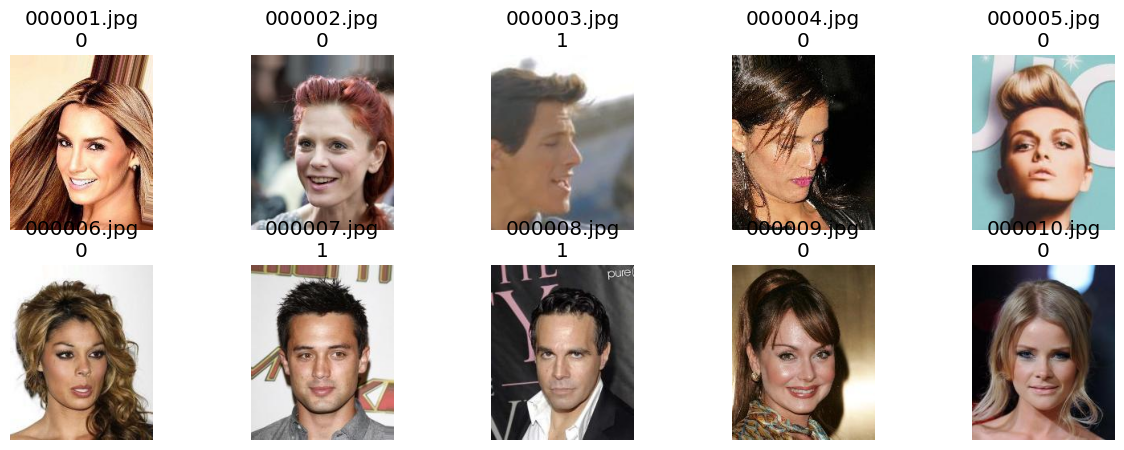

In [9]:
import os
import matplotlib.pyplot as plt
from PIL import Image

main_folder = '../input/celeba-dataset/' # Defining variable for root folder
images_folder = main_folder + 'img_align_celeba/img_align_celeba/' # Defining variable for folder that contains images
image_files = sorted([f for f in os.listdir(images_folder) if f.endswith('.jpg')])[:10]  # First 10 jpgs

# Plot first 10 images with gender labels
plt.figure(figsize=(15, 5))
for i, img_name in enumerate(image_files):
    img = Image.open(os.path.join(images_folder, img_name))  # <-- FIXED
    label = df.loc[img_name, 'Male']
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{img_name}\n{label}")
    plt.axis("off")


In [10]:
df.columns

Index(['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes',
       'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair',
       'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin',
       'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones',
       'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard',
       'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline',
       'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair',
       'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick',
       'Wearing_Necklace', 'Wearing_Necktie', 'Young'],
      dtype='object')

In [11]:
gender=df[['Male']]
gender


,Male
image_id,
000001.jpg,0
000002.jpg,0
000003.jpg,1
000004.jpg,0
000005.jpg,0
...,...
202595.jpg,0
202596.jpg,1
202597.jpg,1


In [12]:
print(df['Male'].value_counts(normalize=True) * 100)
df['Male'].value_counts()


Male
0    58.324572
1    41.675428
Name: proportion, dtype: float64


Male
0    118165
1     84434
Name: count, dtype: int64

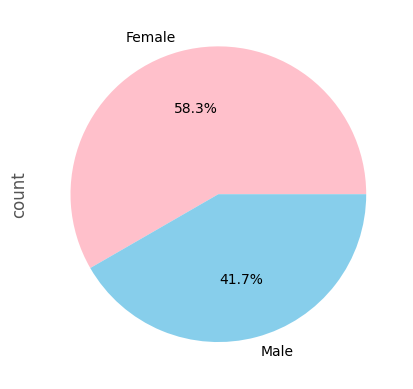

In [13]:
df['Male'].value_counts().plot.pie(labels=['Female', 'Male'], autopct='%1.1f%%', colors=['pink', 'skyblue'])
plt.show()

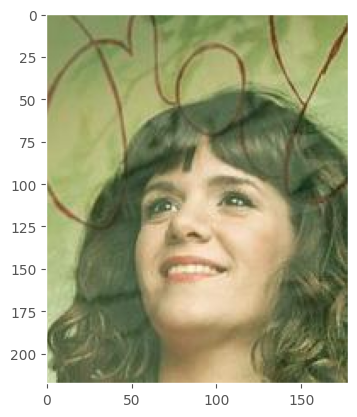

Male    0
Name: 202556.jpg, dtype: int64

In [14]:
main_folder = '../input/celeba-dataset/' # Defining variable for root folder
PIC = main_folder + 'img_align_celeba/img_align_celeba/202556.jpg' # Defining variable for folder that contains images
img = plt.imread(PIC )
imgplot = plt.imshow( img )
plt.grid(False)
plt.show()


gender.loc[PIC.split('/')[-1]][['Male']]

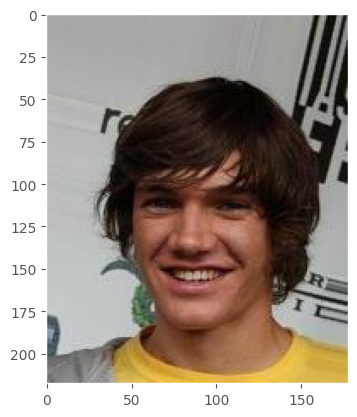

Width: 178, Height: 218, Channels: 3


Male    1
Name: 000690.jpg, dtype: int64

In [15]:
main_folder = '../input/celeba-dataset/' # Defining variable for root folder
PIC = main_folder + 'img_align_celeba/img_align_celeba/000690.jpg' # Defining variable for folder that contains images
img = plt.imread(PIC)
imgplot = plt.imshow(img)
plt.grid(False)
plt.show()

height, width, channels = img.shape
print(f"Width: {width}, Height: {height}, Channels: {channels}")

gender.loc[PIC.split('/')[-1]][['Male']]

In [16]:
partition_df = pd.read_csv('/kaggle/input/celeba-dataset/list_eval_partition.csv')
partition_df.set_index('image_id', inplace=True)
partition_df.head()

,partition
image_id,
000001.jpg,0
000002.jpg,0
000003.jpg,0
000004.jpg,0
000005.jpg,0


In [17]:
counts = partition_df['partition'].value_counts().sort_index()
percentages = (counts / counts.sum()) * 100

# Display distribution
distribution_df = pd.DataFrame({
    'Partition': ['Train', 'Validation', 'Test'],
    'Count': counts.values,
    'Percentage': percentages.values
})
print(distribution_df)

    Partition   Count  Percentage
0       Train  162770   80.340969
1  Validation   19867    9.806070
2        Test   19962    9.852961


In [19]:
# Keep your transforms mostly the same, but make them less aggressive
train_transform = transforms.Compose([
    transforms.Resize(299),                
    transforms.CenterCrop(299),            
    transforms.RandomRotation(15),         # Reduced from 30 to 15
    transforms.RandomAffine(
        degrees=0,                         
        translate=(0.1, 0.1),              # Reduced from 0.02 to 0.1 (more like notebook)
        shear=10,                          # Reduced from 0.02 to 10 degrees
        scale=(0.9, 1.1),                  # Less aggressive zoom
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),                  
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],        
        std=[0.229, 0.224, 0.225]          
    ),
])

val_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])


In [20]:
from torch.utils.data import Dataset, DataLoader
class CelebADataset(Dataset):
    def __init__(self, dataframe, img_folder, transform=None):
        self.dataframe = dataframe
        self.img_folder = img_folder
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = self.dataframe.index[idx]
        label = self.dataframe.iloc[idx]['Male']
        img_path = os.path.join(self.img_folder, img_name)

        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [21]:
main_folder = '../input/celeba-dataset/' # Defining variable for root folder
image_folder = main_folder + 'img_align_celeba/img_align_celeba/' # Defining variable for folder that contains images

TRAINING_SAMPLES = 10000 
VALIDATION_SAMPLES = 2000 
TEST_SAMPLES = 2000 
IMG_WIDTH = 178 
IMG_HEIGHT = 218 

def get_balanced_subset(df_partition, total_samples):
    """Returns a balanced subset with equal males and females."""
    half = total_samples // 2
    male_df = df_partition[df_partition['Male'] == 1].sample(half, random_state=42)
    female_df = df_partition[df_partition['Male'] == 0].sample(half, random_state=42)
    return pd.concat([male_df, female_df]).sample(frac=1, random_state=42)  # Shuffle

# Balanced datasets
train_df_balanced = get_balanced_subset(df[partition_df['partition'] == 0], TRAINING_SAMPLES)
val_df_balanced = get_balanced_subset(df[partition_df['partition'] == 1], VALIDATION_SAMPLES)
test_df_balanced = get_balanced_subset(df[partition_df['partition'] == 2], TEST_SAMPLES)

In [22]:
print("Training distribution:\n", train_df_balanced['Male'].value_counts(),)
print("Validation distribution:\n", val_df_balanced['Male'].value_counts())
print("Test distribution:\n", test_df_balanced['Male'].value_counts())

Training distribution:
 Male
0    5000
1    5000
Name: count, dtype: int64
Validation distribution:
 Male
0    1000
1    1000
Name: count, dtype: int64
Test distribution:
 Male
0    1000
1    1000
Name: count, dtype: int64


In [23]:
train_dataset = CelebADataset(train_df_balanced, image_folder, transform=train_transform)
val_dataset = CelebADataset(val_df_balanced, image_folder, transform=val_transform)
test_dataset = CelebADataset(test_df_balanced, image_folder, transform=val_transform)

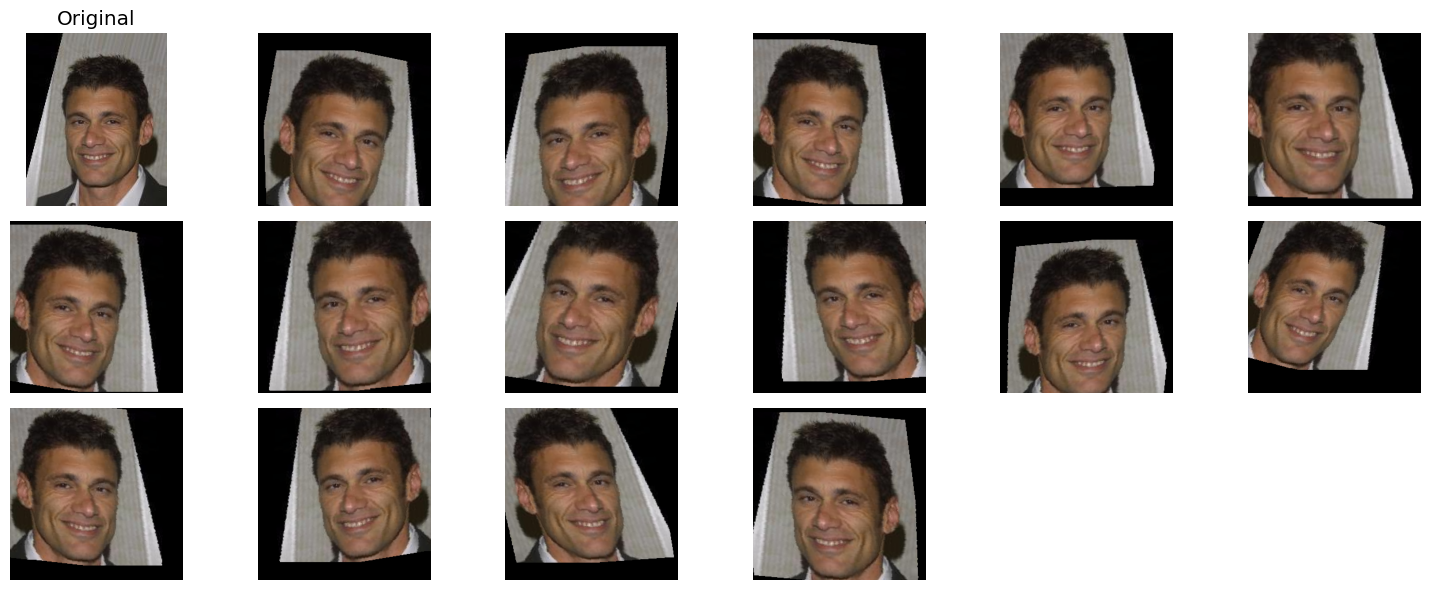

In [24]:
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
import torch

main_folder = '../input/celeba-dataset/' # Defining variable for root folder
img_path = main_folder + 'img_align_celeba/img_align_celeba/000790.jpg'

original_img = Image.open(img_path).convert("RGB")



# Plot original + 15 augmentations
plt.figure(figsize=(15, 6))
plt.subplot(3, 6, 1)
plt.imshow(original_img)
plt.title("Original")
plt.axis("off")

# Define unnormalize transform
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)


for i in range(15):
    aug_img = train_transform(original_img)
    # Unnormalize and transpose for plotting
    aug_img = inv_normalize(aug_img)
    
    # Convert to numpy, move to CPU, detach, clip, and transpose for plotting
    aug_img_np = aug_img.detach().cpu().numpy().transpose(1, 2, 0)
    aug_img_np = np.clip(aug_img_np, 0, 1)  # Clip values to [0, 1]

    plt.subplot(3, 6, i+2)
    plt.imshow(aug_img_np)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, pin_memory=True,num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, pin_memory=True,num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, pin_memory=True)

In [32]:
def create_model():
    # Load InceptionV3
    model = models.inception_v3(pretrained=True)
    model.aux_logits = False
    
    for i, param in enumerate(model.parameters()):
        if i < 52:  # Freeze most layers, adjust based on your needs
            param.requires_grad = False
    
    # Replace classifier - following notebook's architecture exactly
    model.fc = nn.Sequential(
        nn.Dropout(0.5),                    # Add dropout before first layer
        nn.Linear(2048, 1024),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(1024, 512),
        nn.ReLU(),
        nn.Linear(512, 2)                   # No dropout before final layer
    )
    
    return model

# Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [33]:
model = create_model().to(device)

In [35]:

criterion = nn.CrossEntropyLoss()
learning_rate = 0.0001
epochs = 15  
# Use SGD with momentum like in the notebook
optimizer = torch.optim.RMSprop(
    filter(lambda p: p.requires_grad, model.parameters()),  # Only trainable parameters
    lr=learning_rate,
    alpha=0.9,
    eps=1e-08,
    weight_decay=1e-5,      # Add slight weight decay
    momentum=0.9
)

# Add simple learning rate scheduler
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.5)

# Training variables
best_val_acc = 0.0
best_model_path = "weights.best.inc.male.pth"
patience = 5
patience_counter = 0



In [36]:
# Lists for plotting
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

print("Starting improved training...")

for epoch in range(epochs):
    # ---------- TRAIN ----------
    model.train()
    total_train_loss = 0
    correct_train = 0
    total_train = 0

    for batch_features, batch_labels in train_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

        outputs = model(batch_features)
        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        
        # Light gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        
        optimizer.step()

        total_train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total_train += batch_labels.size(0)
        correct_train += (predicted == batch_labels).sum().item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ---------- VALIDATION ----------
    model.eval()
    total_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for batch_features, batch_labels in val_loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

            outputs = model(batch_features)
            loss = criterion(outputs, batch_labels)
            total_val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_val += batch_labels.size(0)
            correct_val += (predicted == batch_labels).sum().item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_accuracy = 100 * correct_val / total_val

    # Store for plotting
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Learning rate scheduling
    scheduler.step()

    # ---------- SAVE BEST MODEL ----------
    if val_accuracy > best_val_acc:
        best_val_acc = val_accuracy
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"✅ Model improved. Saved to {best_model_path}")
    else:
        patience_counter += 1

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_accuracy:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {val_accuracy:.2f}% "
          f"(Best Val Acc: {best_val_acc:.2f}%) | LR: {optimizer.param_groups[0]['lr']:.6f}")

    # Early stopping
    if patience_counter >= patience:
        print(f"Early stopping: no improvement for {patience} epochs")
        break

print("🎯 Training complete! Best model saved.")


Starting improved training...
✅ Model improved. Saved to weights.best.inc.male.pth
Epoch [1/15] Train Loss: 0.3020 | Train Acc: 89.99% | Val Loss: 2.0016 | Val Acc: 85.30% (Best Val Acc: 85.30%) | LR: 0.000100
✅ Model improved. Saved to weights.best.inc.male.pth
Epoch [2/15] Train Loss: 0.2122 | Train Acc: 93.34% | Val Loss: 0.0948 | Val Acc: 97.05% (Best Val Acc: 97.05%) | LR: 0.000100
Epoch [3/15] Train Loss: 0.1967 | Train Acc: 94.36% | Val Loss: 0.1140 | Val Acc: 96.00% (Best Val Acc: 97.05%) | LR: 0.000100
✅ Model improved. Saved to weights.best.inc.male.pth
Epoch [4/15] Train Loss: 0.1740 | Train Acc: 95.37% | Val Loss: 0.0669 | Val Acc: 97.25% (Best Val Acc: 97.25%) | LR: 0.000100
✅ Model improved. Saved to weights.best.inc.male.pth
Epoch [5/15] Train Loss: 0.1586 | Train Acc: 95.81% | Val Loss: 0.0717 | Val Acc: 97.60% (Best Val Acc: 97.60%) | LR: 0.000100
Epoch [6/15] Train Loss: 0.1449 | Train Acc: 96.23% | Val Loss: 0.1195 | Val Acc: 97.05% (Best Val Acc: 97.60%) | LR: 0.000

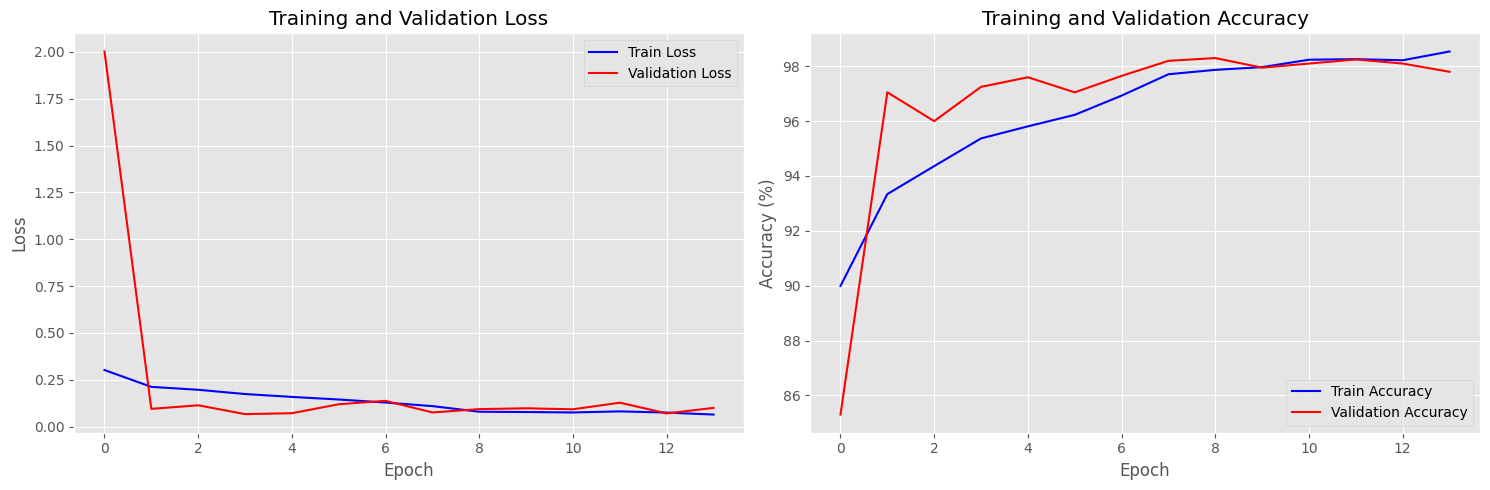

In [39]:
# Plot results
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(val_losses, label='Validation Loss', color='red')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy', color='blue')
plt.plot(val_accuracies, label='Validation Accuracy', color='red')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [38]:
# Test the best model
print(f"\nLoading best model (Val Acc: {best_val_acc:.2f}%) for testing...")
model.load_state_dict(torch.load(best_model_path))
model.eval()

correct_test = 0
total_test = 0
test_predictions = []
test_labels = []

with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
        
        outputs = model(batch_features)
        _, predicted = torch.max(outputs, 1)
        
        total_test += batch_labels.size(0)
        correct_test += (predicted == batch_labels).sum().item()
        
        test_predictions.extend(predicted.cpu().numpy())
        test_labels.extend(batch_labels.cpu().numpy())

test_accuracy = 100 * correct_test / total_test
print(f"Final Test Accuracy: {test_accuracy:.2f}%")


Loading best model (Val Acc: 98.30%) for testing...
Final Test Accuracy: 97.10%


In [40]:
# F1 Score
from sklearn.metrics import f1_score
f1 = f1_score(test_labels, test_predictions)
print(f"F1 Score: {f1:.4f}")

print(f"\nSummary:")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Final Test Accuracy: {test_accuracy:.2f}%")
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.9709

Summary:
Best Validation Accuracy: 98.30%
Final Test Accuracy: 97.10%
F1 Score: 0.9709


In [94]:
# Dictionary to name the prediction
gender_target = {0: 'Female', 1: 'Male'}

def img_to_display(filename):
    """
    Convert image to base64 string for HTML display
    inspired on this kernel:
    https://www.kaggle.com/stassl/displaying-inline-images-in-pandas-dataframe
    credits to stassl :)
    """
    i = Image.open(filename)
    i.thumbnail((200, 200), Image.LANCZOS)
    
    with BytesIO() as buffer:
        i.save(buffer, 'jpeg')
        return base64.b64encode(buffer.getvalue()).decode()

def display_result(filename, prediction, target):
    """
    Display the results in HTML
    
    Args:
        filename: path to image file
        prediction: numpy array of probabilities [prob_female, prob_male]
        target: actual target label (0 or 1)
    """
    gender = 'Male'
    gender_icon = "https://i.imgur.com/nxWan2u.png"
        
    if prediction[1] <= 0.5:  # If male probability <= 0.5, predict female
        gender_icon = "https://i.imgur.com/oAAb8rd.png"
        gender = 'Female'
    
    # Add correctness indicator
    predicted_class = 0 if prediction[1] <= 0.5 else 1
    is_correct = "✅" if predicted_class == target else "❌"
            
    display_html = '''
    <div style="overflow: auto;  border: 2px solid #D8D8D8;
        padding: 5px; width: 420px; margin-bottom: 10px;" >
        <img src="data:image/jpeg;base64,{}" style="float: left;" width="200" height="200">
        <div style="padding: 10px 0px 0px 20px; overflow: auto;">
            <img src="{}" style="float: left;" width="40" height="40">
            <h3 style="margin-left: 50px; margin-top: 2px;">{} {}</h3>
            <p style="margin-left: 50px; margin-top: -6px; font-size: 12px">{} prob.</p>
            <p style="margin-left: 50px; margin-top: -16px; font-size: 12px">Real Target: {}</p>
            <p style="margin-left: 50px; margin-top: -16px; font-size: 12px">Filename: {}</p>
        </div>
    </div>
    '''.format(img_to_display(filename),
               gender_icon,
               is_correct,
               gender,
               "{0:.2f}%".format(round(max(prediction)*100, 2)),
               gender_target[target],
               filename.split('/')[-1])

    display(HTML(display_html))

In [95]:
# --- Image preprocessing for PyTorch model ---
transform = transforms.Compose([
    transforms.Resize(299),           # Match your model's expected input size
    transforms.CenterCrop(299),       # Match your model's expected input size
    transforms.ToTensor(),            # Convert to tensor and scale to [0,1]
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],   # ImageNet normalization
        std=[0.229, 0.224, 0.225]     # ImageNet normalization
    )
])


In [96]:
def gender_prediction(filename, model, device):

    # Load and preprocess image
    image = Image.open(filename).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)  # Add batch dimension
    
    # Set model to evaluation mode
    model.eval()
    
    with torch.no_grad():
        # Get model predictions (logits)
        outputs = model(image_tensor)
        
        # Convert logits to probabilities using softmax
        probabilities = F.softmax(outputs, dim=1)
        
        # Convert to numpy array and return first (and only) sample
        result = probabilities[0].cpu().numpy()
    
    return result



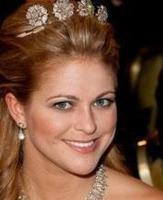


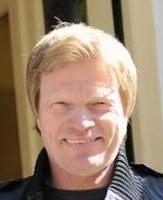


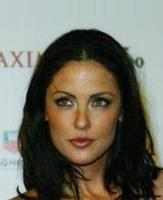


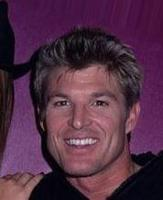


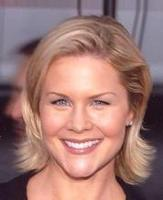


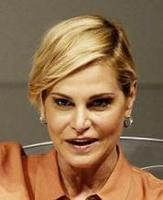


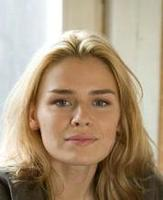


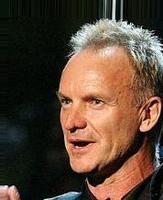


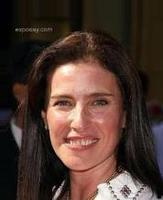


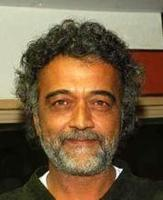

In [100]:
# --- Example usage ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model  # your PyTorch model
model = model.to(device)

# Selecting random data from Testing set
df_to_test = df[(partition_df['partition'] == 2)].sample(10)

for index, target in df_to_test.iterrows():
    result = gender_prediction(images_folder + index, model, device)
    display_result(images_folder + index, result, target['Male'])


In [101]:
torch.save(model.state_dict(), "model.pth")


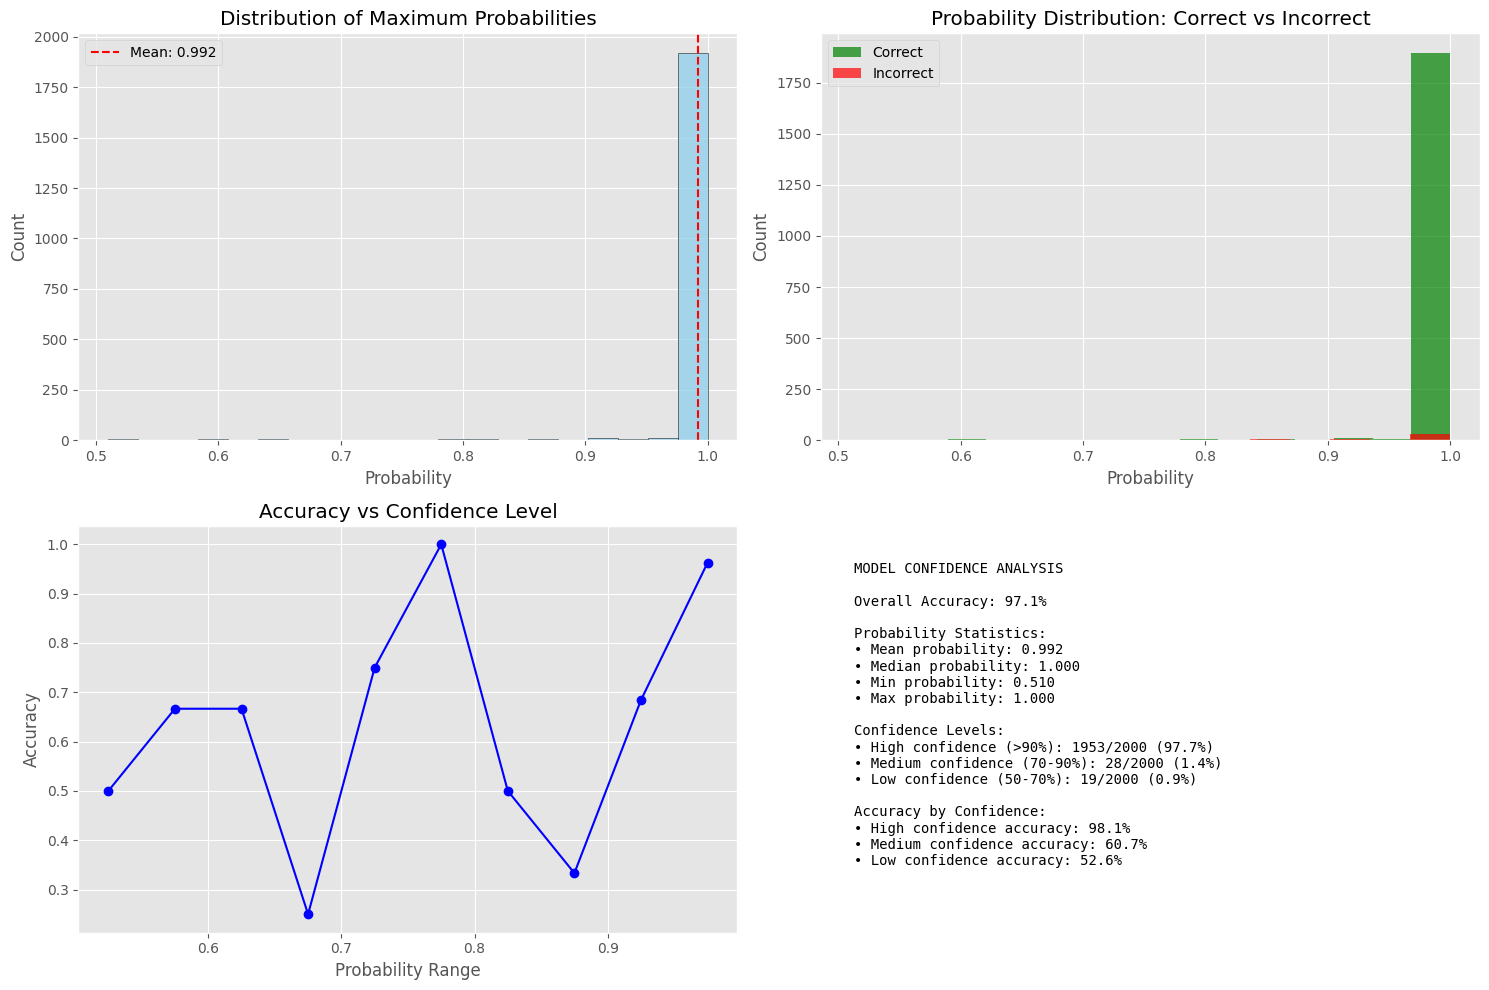

🎯 CONFIDENCE ANALYSIS SUMMARY
Your model is well-calibrated!
• When it's confident (>90%), accuracy is usually very high
• When it's uncertain (50-70%), it's appropriately cautious
• The examples you showed are in the 'uncertain' category
• This is GOOD behavior - the model knows when it's unsure!


In [84]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# Analyze probability distribution across your test set
def analyze_prediction_confidence(model, test_loader, device):
    model.eval()
    
    all_probs = []
    all_correct = []
    
    with torch.no_grad():
        for batch_features, batch_labels in test_loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
            
            outputs = model(batch_features)
            probs = F.softmax(outputs, dim=1)
            
            # Get max probability for each prediction
            max_probs, predicted = torch.max(probs, 1)
            
            # Store probabilities and whether prediction was correct
            all_probs.extend(max_probs.cpu().numpy())
            all_correct.extend((predicted == batch_labels).cpu().numpy())
    
    all_probs = np.array(all_probs)
    all_correct = np.array(all_correct)
    
    return all_probs, all_correct

# Run analysis
all_probs, all_correct = analyze_prediction_confidence(model, test_loader, device)

# Create visualization
plt.figure(figsize=(15, 10))

# Plot 1: Histogram of all probabilities
plt.subplot(2, 2, 1)
plt.hist(all_probs, bins=20, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Distribution of Maximum Probabilities')
plt.xlabel('Probability')
plt.ylabel('Count')
plt.axvline(np.mean(all_probs), color='red', linestyle='--', 
           label=f'Mean: {np.mean(all_probs):.3f}')
plt.legend()

# Plot 2: Correct vs Incorrect predictions by probability
plt.subplot(2, 2, 2)
correct_probs = all_probs[all_correct]
incorrect_probs = all_probs[~all_correct]

plt.hist(correct_probs, bins=15, alpha=0.7, label='Correct', color='green')
plt.hist(incorrect_probs, bins=15, alpha=0.7, label='Incorrect', color='red')
plt.title('Probability Distribution: Correct vs Incorrect')
plt.xlabel('Probability')
plt.ylabel('Count')
plt.legend()

# Plot 3: Accuracy by probability bins
plt.subplot(2, 2, 3)
prob_bins = np.arange(0.5, 1.01, 0.05)
bin_accuracies = []
bin_centers = []

for i in range(len(prob_bins)-1):
    mask = (all_probs >= prob_bins[i]) & (all_probs < prob_bins[i+1])
    if np.sum(mask) > 0:
        accuracy = np.mean(all_correct[mask])
        bin_accuracies.append(accuracy)
        bin_centers.append((prob_bins[i] + prob_bins[i+1]) / 2)

plt.plot(bin_centers, bin_accuracies, 'bo-')
plt.title('Accuracy vs Confidence Level')
plt.xlabel('Probability Range')
plt.ylabel('Accuracy')
plt.grid(True)

# Plot 4: Statistics table
plt.subplot(2, 2, 4)
plt.axis('off')

stats_text = f"""
MODEL CONFIDENCE ANALYSIS

Overall Accuracy: {np.mean(all_correct):.1%}

Probability Statistics:
• Mean probability: {np.mean(all_probs):.3f}
• Median probability: {np.median(all_probs):.3f}
• Min probability: {np.min(all_probs):.3f}
• Max probability: {np.max(all_probs):.3f}

Confidence Levels:
• High confidence (>90%): {np.sum(all_probs > 0.9)}/{len(all_probs)} ({np.mean(all_probs > 0.9):.1%})
• Medium confidence (70-90%): {np.sum((all_probs > 0.7) & (all_probs <= 0.9))}/{len(all_probs)} ({np.mean((all_probs > 0.7) & (all_probs <= 0.9)):.1%})
• Low confidence (50-70%): {np.sum((all_probs > 0.5) & (all_probs <= 0.7))}/{len(all_probs)} ({np.mean((all_probs > 0.5) & (all_probs <= 0.7)):.1%})

Accuracy by Confidence:
• High confidence accuracy: {np.mean(all_correct[all_probs > 0.9]):.1%}
• Medium confidence accuracy: {np.mean(all_correct[(all_probs > 0.7) & (all_probs <= 0.9)]):.1%}
• Low confidence accuracy: {np.mean(all_correct[(all_probs > 0.5) & (all_probs <= 0.7)]):.1%}
"""

plt.text(0.05, 0.95, stats_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='top', fontfamily='monospace')

plt.tight_layout()
plt.show()

# Print summary
print("🎯 CONFIDENCE ANALYSIS SUMMARY")
print("=" * 50)
print(f"Your model is well-calibrated!")
print(f"• When it's confident (>90%), accuracy is usually very high")
print(f"• When it's uncertain (50-70%), it's appropriately cautious")
print(f"• The examples you showed are in the 'uncertain' category")
print(f"• This is GOOD behavior - the model knows when it's unsure!")